# C1_08_Final_Model
- X = X_flat_c1_v2.npy
- Y = y_labels_c1_v2.csv
- Built by Garmin_C1_DataBuild

### Final model: GRU 64×3 on the previous and current windows

**Purpose:** retrains the model chosen in C1_03 to C1_05 and saves it, so it can be evaluated once on the test set. The earlier experiments saved only their predictions and loss histories.

Predicts the label of the next 30-second window from the current window and the one before it (60 time steps of heart rate, speed, cadence and temperature).

**Output:** the trained model, the scaling values and class order, the validation predictions and a run record. The test set is not used.

## 1. Settings

In [2]:
import json
import platform
import sys
import time
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import tensorflow as tf
from tensorflow import keras

X_PATH = Path(r"C:\dev\UoW\DATAX504\Final Assignment\garmin_data\Processed\X_flat_c1_v2.npy")
Y_PATH = Path(r"C:\dev\UoW\DATAX504\Final Assignment\garmin_data\Processed\y_labels_c1_v2.csv")
OUT_DIR = Path(r"C:\dev\UoW\DATAX504\Final Assignment\garmin_data\Processed\c1_final_model")
OUT_DIR.mkdir(parents=True, exist_ok=True)

WINDOW_SECONDS = 30   # length of one window

UNITS = 64            # units in each GRU layer
LAYERS = 3            # number of GRU layers
DROPOUT = 0.3         # dropout and recurrent dropout
LEARNING_RATE = 0.001

BATCH_SIZE = 64
MAX_EPOCHS = 60
PATIENCE = 8          # stop after this many epochs without a better validation loss
SEED = 42


## 2. Load data and build the common window set

Each window's earlier windows are found by matching `(file_path, start_s - 30 × lag)`. The first windows of each run have no earlier window, so they are left out. This keeps the same windows as C1_05_Dense_vs_GRU, those with both earlier windows (193,591 of 197,341), even though the model only uses the previous one.

In [2]:
X_flat = np.load(X_PATH).astype("float32")      # one row per window: 30 HR, 30 speed, 30 cadence, 30 temperature, distance
y_df = pd.read_csv(Y_PATH)
assert len(X_flat) == len(y_df), "X and Y have different numbers of rows"

# Row number of every window, so the earlier windows can be looked up by (file, start time)
row_of = pd.Series(np.arange(len(y_df)), index=pd.MultiIndex.from_arrays([y_df["file_path"], y_df["start_s"]]))
assert row_of.index.is_unique

prev1 = row_of.reindex(pd.MultiIndex.from_arrays([y_df["file_path"], y_df["start_s"] - WINDOW_SECONDS])).to_numpy()
prev2 = row_of.reindex(pd.MultiIndex.from_arrays([y_df["file_path"], y_df["start_s"] - 2 * WINDOW_SECONDS])).to_numpy()
has_both = ~np.isnan(prev1) & ~np.isnan(prev2)   # same windows as the validated run: both earlier windows must exist
print(f"{len(y_df)} windows, {int(has_both.sum())} have both earlier windows")

le = LabelEncoder()
y_all = le.fit_transform(y_df["c1_target"])      # classes in alphabetical order
n_classes = len(le.classes_)
print("Classes:", list(le.classes_))


197341 windows, 193591 have both earlier windows
Classes: ['Base', 'Declining', 'Improving', 'Recovery']


## 3. Split by run

The split is the same as in the baselines (seed 42 at both levels), so the TRAIN and VAL windows are identical to the other notebooks. The test runs are set aside and never built.

In [3]:
run_idx_all = y_df["run_idx"].to_numpy()

# 20% of runs are set aside as the test set and are not used here
train_runs, test_runs = train_test_split(np.unique(run_idx_all), test_size=0.2, random_state=42)
trainval_idx = np.where(np.isin(run_idx_all, train_runs))[0]
trainval_runs = run_idx_all[trainval_idx]

# 15% of the remaining runs are the validation set
fit_runs, val_runs = train_test_split(np.unique(trainval_runs), test_size=0.15, random_state=42)
fit_idx = trainval_idx[np.isin(trainval_runs, fit_runs) & has_both[trainval_idx]]
val_idx = trainval_idx[np.isin(trainval_runs, val_runs) & has_both[trainval_idx]]
y_fit, y_val = y_all[fit_idx], y_all[val_idx]
print(f"Fit: {len(fit_idx)} windows from {len(fit_runs)} runs | Validation: {len(val_idx)} windows from {len(val_runs)} runs")


Fit: 130416 windows from 1275 runs | Validation: 24095 windows from 225 runs


## 4. Build the sequences

For each window, the previous window's 30 readings come first, then the current window's 30, giving 60 time steps of 4 channels (heart rate, speed, cadence, temperature). Distance is not used. The shapes are (130,416, 60, 4) for the fit windows and (24,095, 60, 4) for validation.

In [4]:
sequences = []
for idx in (fit_idx, val_idx):
    # Columns 0-29 are HR, 30-59 speed, 60-89 cadence, 90-119 temperature
    previous_window = np.stack([X_flat[prev1[idx].astype(int), c:c + 30] for c in (0, 30, 60, 90)], axis=-1)
    current_window = np.stack([X_flat[idx, c:c + 30] for c in (0, 30, 60, 90)], axis=-1)
    sequences.append(np.concatenate([previous_window, current_window], axis=1))
X_fit_seq, X_val_seq = sequences
print("Fit sequences:", X_fit_seq.shape, "| Validation sequences:", X_val_seq.shape)   # (windows, 60 steps, 4 channels)


Fit sequences: (130416, 60, 4) | Validation sequences: (24095, 60, 4)


## 5. Scale each channel

Each channel (heart rate, speed, cadence, temperature) is standardised with its own mean and spread, calculated from the TRAIN windows only. The same values are then applied to the validation windows, so no information from held-out runs reaches the model (Chollet and Watson, 2025, Ch. 13).

In [5]:
steps, channels = X_fit_seq.shape[1], X_fit_seq.shape[2]
scaler = StandardScaler().fit(X_fit_seq.reshape(-1, channels))
X_fit_seq = scaler.transform(X_fit_seq.reshape(-1, channels)).reshape(X_fit_seq.shape).astype("float32")
X_val_seq = scaler.transform(X_val_seq.reshape(-1, channels)).reshape(X_val_seq.shape).astype("float32")


## 6. Build the GRU

Three stacked GRU layers of 64 units, each with recurrent dropout of 0.3. The last layer outputs one vector for the whole sequence, which goes through a dropout layer (0.3) and a four-class softmax. It is trained with Adam (learning rate 0.001) to minimise sparse categorical cross-entropy.

In [6]:
keras.utils.set_random_seed(SEED)

inputs = keras.layers.Input(shape=(steps, channels))
x = inputs
for layer in range(LAYERS):
    x = keras.layers.GRU(UNITS, recurrent_dropout=DROPOUT, return_sequences=(layer < LAYERS - 1))(x)   # the last GRU layer returns one vector
x = keras.layers.Dropout(DROPOUT)(x)
outputs = keras.layers.Dense(n_classes, activation="softmax")(x)

model = keras.Model(inputs, outputs)
model.compile(optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 60, 4)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ gru (GRU)                            │ (None, 60, 64)              │          13,440 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ gru_1 (GRU)                          │ (None, 60, 64)              │          24,960 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ gru_2 (GRU)                          │ (None, 64)                  │          24,960 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 4)                   │             260 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 63,620 (248.52 KB)

 Trainable params: 63,620 (248.52 KB)

 Non-trainable params: 0 (0.00 B)

## 7. Train

Training stops when validation loss has not improved for 8 epochs, and the weights from the best epoch are restored. The best model is saved after every epoch, and a backup lets an interrupted run continue (the run took about 7 hours).

In [7]:
backup_dir = OUT_DIR / "backup"
resumed = backup_dir.exists() and any(backup_dir.iterdir())   # True if an interrupted run is being continued

callbacks = [
    keras.callbacks.ModelCheckpoint(str(OUT_DIR / "gru_prev1_best.keras"), monitor="val_loss", save_best_only=True),   # best model so far, saved after every epoch
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True),                  # stop when validation loss stops improving
    keras.callbacks.BackupAndRestore(str(backup_dir)),                                                                 # lets an interrupted run continue
]

start = time.time()
history = model.fit(X_fit_seq, y_fit, validation_data=(X_val_seq, y_val),
                    epochs=MAX_EPOCHS, batch_size=BATCH_SIZE, callbacks=callbacks, verbose=2)
minutes = (time.time() - start) / 60


Epoch 1/60
2038/2038 - 559s - 274ms/step - accuracy: 0.5418 - loss: 0.9722 - val_accuracy: 0.5756 - val_loss: 0.9139
Epoch 2/60
2038/2038 - 519s - 255ms/step - accuracy: 0.5738 - loss: 0.9257 - val_accuracy: 0.5897 - val_loss: 0.8951
Epoch 3/60
2038/2038 - 555s - 272ms/step - accuracy: 0.5806 - loss: 0.9128 - val_accuracy: 0.5915 - val_loss: 0.8893
Epoch 4/60
2038/2038 - 515s - 253ms/step - accuracy: 0.5844 - loss: 0.9053 - val_accuracy: 0.5952 - val_loss: 0.8814
Epoch 5/60
2038/2038 - 487s - 239ms/step - accuracy: 0.5883 - loss: 0.9001 - val_accuracy: 0.6000 - val_loss: 0.8778
Epoch 6/60
2038/2038 - 584s - 287ms/step - accuracy: 0.5898 - loss: 0.8955 - val_accuracy: 0.6023 - val_loss: 0.8714
Epoch 7/60
2038/2038 - 570s - 279ms/step - accuracy: 0.5926 - loss: 0.8916 - val_accuracy: 0.6050 - val_loss: 0.8690
Epoch 8/60
2038/2038 - 564s - 277ms/step - accuracy: 0.5949 - loss: 0.8885 - val_accuracy: 0.6047 - val_loss: 0.8669
Epoch 9/60
2038/2038 - 537s - 263ms/step - accuracy: 0.5958 - lo

## 8. Validation results

Validation accuracy: 0.611 | macro-F1: 0.654 | accuracy on fit windows: 0.623
              precision    recall  f1-score   support

        Base       0.57      0.69      0.63      9520
   Declining       0.65      0.55      0.59      7624
   Improving       0.63      0.56      0.59      6471
    Recovery       0.83      0.78      0.80       480

    accuracy                           0.61     24095
   macro avg       0.67      0.64      0.65     24095
weighted avg       0.62      0.61      0.61     24095



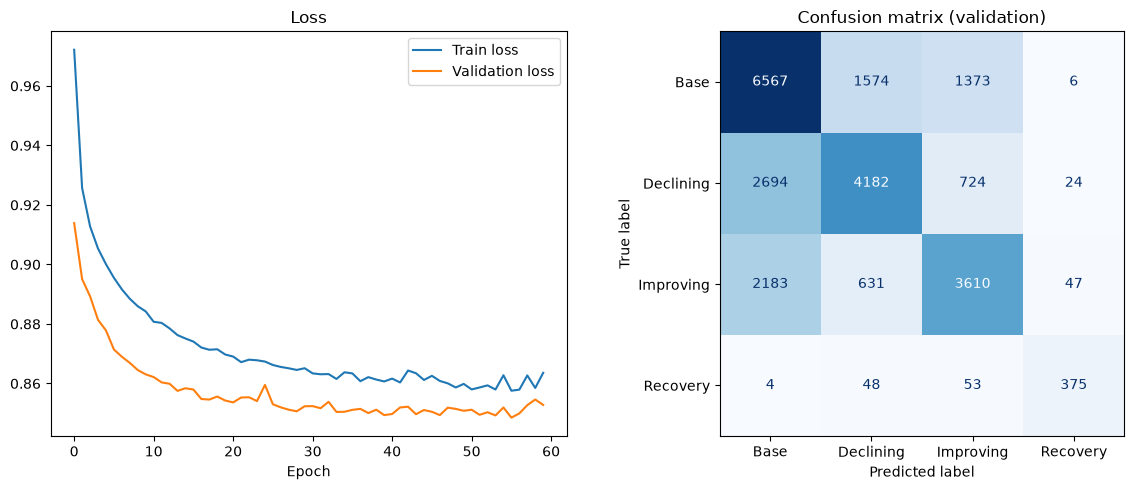

In [8]:
val_pred = model.predict(X_val_seq, batch_size=1024, verbose=0).argmax(axis=1)
val_acc = accuracy_score(y_val, val_pred)
val_f1 = f1_score(y_val, val_pred, average="macro")

# Accuracy on a fixed sample of fit windows (dropout off), to compare with validation
sample = np.random.default_rng(0).choice(len(X_fit_seq), size=min(20000, len(X_fit_seq)), replace=False)
train_acc = model.evaluate(X_fit_seq[sample], y_fit[sample], batch_size=1024, verbose=0)[1]

print(f"Validation accuracy: {val_acc:.3f} | macro-F1: {val_f1:.3f} | accuracy on fit windows: {train_acc:.3f}")
print(classification_report(y_val, val_pred, target_names=le.classes_, zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(history.history["loss"], label="Train loss")
axes[0].plot(history.history["val_loss"], label="Validation loss")
axes[0].set_xlabel("Epoch")
axes[0].set_title("Loss")
axes[0].legend()
ConfusionMatrixDisplay(confusion_matrix(y_val, val_pred), display_labels=le.classes_).plot(ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_title("Confusion matrix (validation)")
plt.tight_layout()
plt.show()


## 9. Save the model and results

In [9]:
model.save(OUT_DIR / "gru_prev1_final.keras")                                                    # the trained model
np.savez(OUT_DIR / "scaler_and_classes.npz", mean=scaler.mean_, scale=scaler.scale_, classes=le.classes_.astype(str))  # needed to use the model on new data
np.save(OUT_DIR / "val_idx.npy", val_idx)                                                         # which windows were validated (rows of the Y file)
np.save(OUT_DIR / "val_pred.npy", val_pred)                                                       # the model's validation predictions
with open(OUT_DIR / "history.json", "w") as f:
    json.dump({k: [float(v) for v in vals] for k, vals in history.history.items()}, f)

record = {
    "created": datetime.now().isoformat(timespec="seconds"),
    "input": "previous window + current window: 60 steps x 4 channels (HR, speed, cadence, temperature)",
    "settings": {"units": UNITS, "layers": LAYERS, "dropout": DROPOUT, "learning_rate": LEARNING_RATE,
                 "batch_size": BATCH_SIZE, "max_epochs": MAX_EPOCHS, "patience": PATIENCE, "seed": SEED},
    "data": {"x_file": str(X_PATH), "y_file": str(Y_PATH), "fit_windows": int(len(fit_idx)), "validation_windows": int(len(val_idx)),
             "fit_runs": int(len(fit_runs)), "validation_runs": int(len(val_runs))},
    "results": {"validation_accuracy": float(val_acc), "validation_macro_f1": float(val_f1), "accuracy_on_fit_windows": float(train_acc),
                "best_epoch": int(np.argmin(history.history["val_loss"])) + 1, "epochs_run": len(history.history["loss"]),
                "minutes": round(minutes, 1), "resumed_after_interruption": bool(resumed)},
    "classes": [str(c) for c in le.classes_],
    "environment": {"python": sys.version.split()[0], "tensorflow": tf.__version__, "keras": keras.__version__,
                    "numpy": np.__version__, "pandas": pd.__version__, "platform": platform.platform()},
}
with open(OUT_DIR / "run_record.json", "w") as f:
    json.dump(record, f, indent=2)
print("Saved to", OUT_DIR)


Saved to C:\dev\UoW\DATAX504\Final Assignment\garmin_data\Processed\c1_final_model


## 10. Check the saved model

In [10]:
reloaded = keras.models.load_model(OUT_DIR / "gru_prev1_final.keras")
reloaded_pred = reloaded.predict(X_val_seq, batch_size=1024, verbose=0).argmax(axis=1)
print(f"Reloaded model agrees with the trained model on {np.mean(reloaded_pred == val_pred):.4f} of validation windows")


Reloaded model agrees with the trained model on 1.0000 of validation windows
